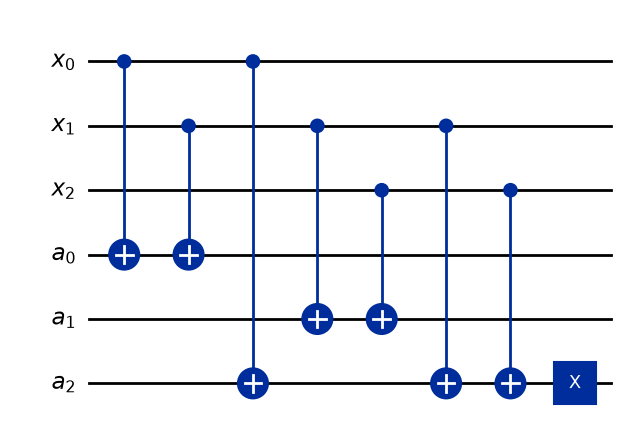

In [1]:
# Built-in modules
import math

# Imports from Qiskit
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.circuit.library import grover_operator, MCMTGate, ZGate
from qiskit.visualization import plot_distribution
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

x = QuantumRegister(3, "x")
a = QuantumRegister(3, "a")
qc = QuantumCircuit(x, a)

# Clause 1: x0 XOR x1 -> stored in a[0]
qc.cx(x[0], a[0])
qc.cx(x[1], a[0])

# Clause 2: x1 XOR x2 -> stored in a[1]
qc.cx(x[1], a[1])
qc.cx(x[2], a[1])

# Clause 3: NOT(x0 XOR x1 XOR x2) -> stored in a[2]
qc.cx(x[0], a[2])
qc.cx(x[1], a[2])
qc.cx(x[2], a[2])
qc.x(a[2])  # The NOT

qc.draw("mpl", style="iqp")

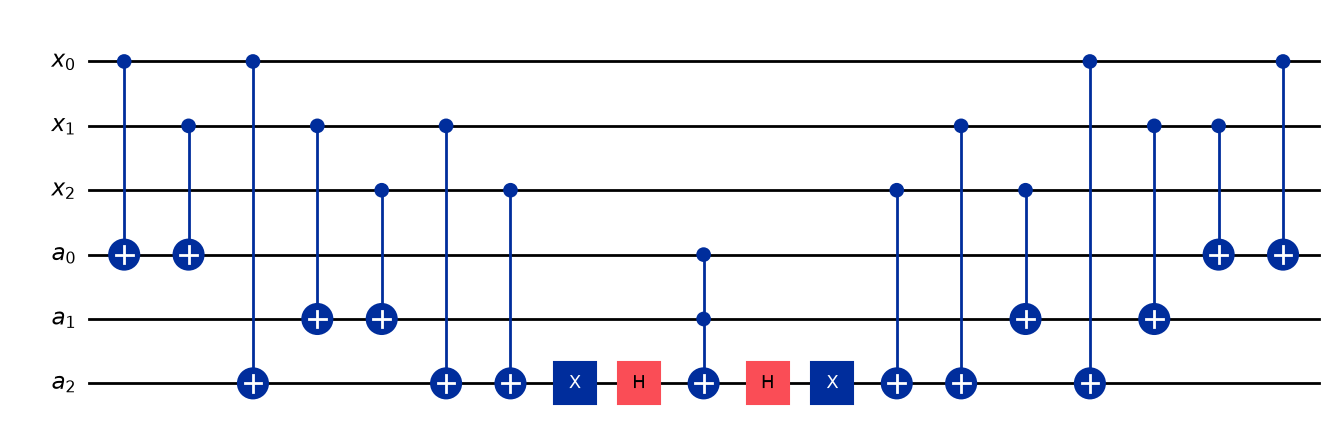

In [2]:
# Multi-controlled Z: flip phase if all workspace qubits are |1>
qc.h(a[2])
qc.mcx([a[0], a[1]], a[2])
qc.h(a[2])

# Uncompute clause 3: NOT(x0 XOR x1 XOR x2)
qc.x(a[2])
qc.cx(x[2], a[2])
qc.cx(x[1], a[2])
qc.cx(x[0], a[2])

# Uncompute clause 2: x1 XOR x2
qc.cx(x[2], a[1])
qc.cx(x[1], a[1])

# Uncompute clause 1: x0 XOR x1
qc.cx(x[1], a[0])
qc.cx(x[0], a[0])

qc.draw("mpl", style="iqp")

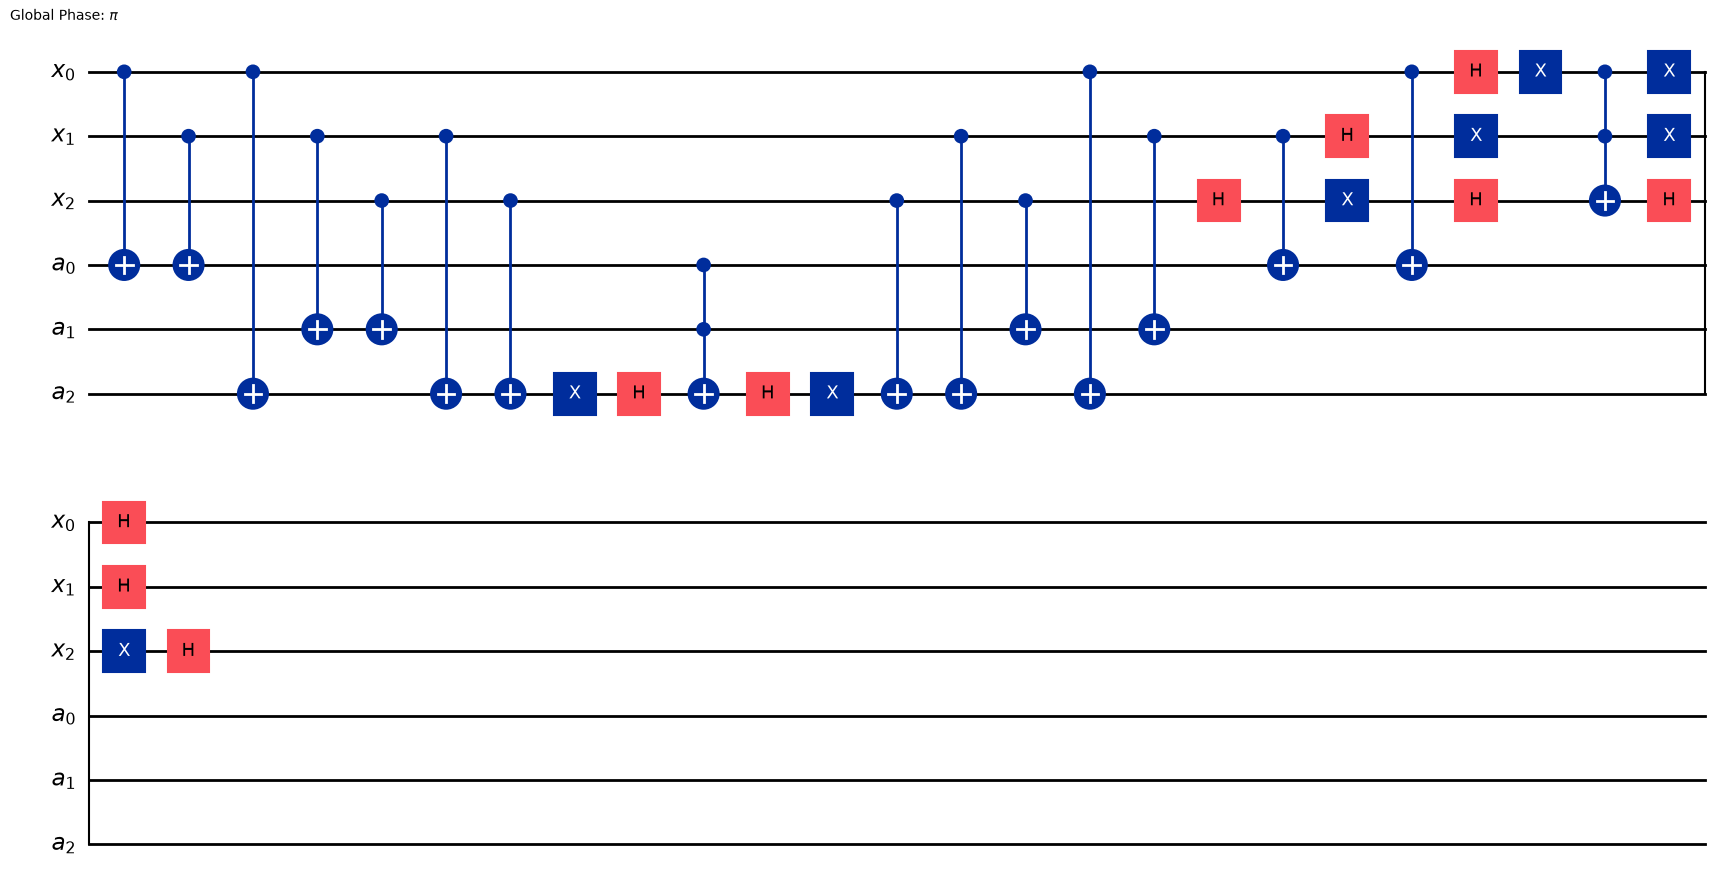

In [3]:
grover_op = grover_operator(qc, reflection_qubits=x)
grover_op.decompose(reps=0).draw(output="mpl", style="iqp")

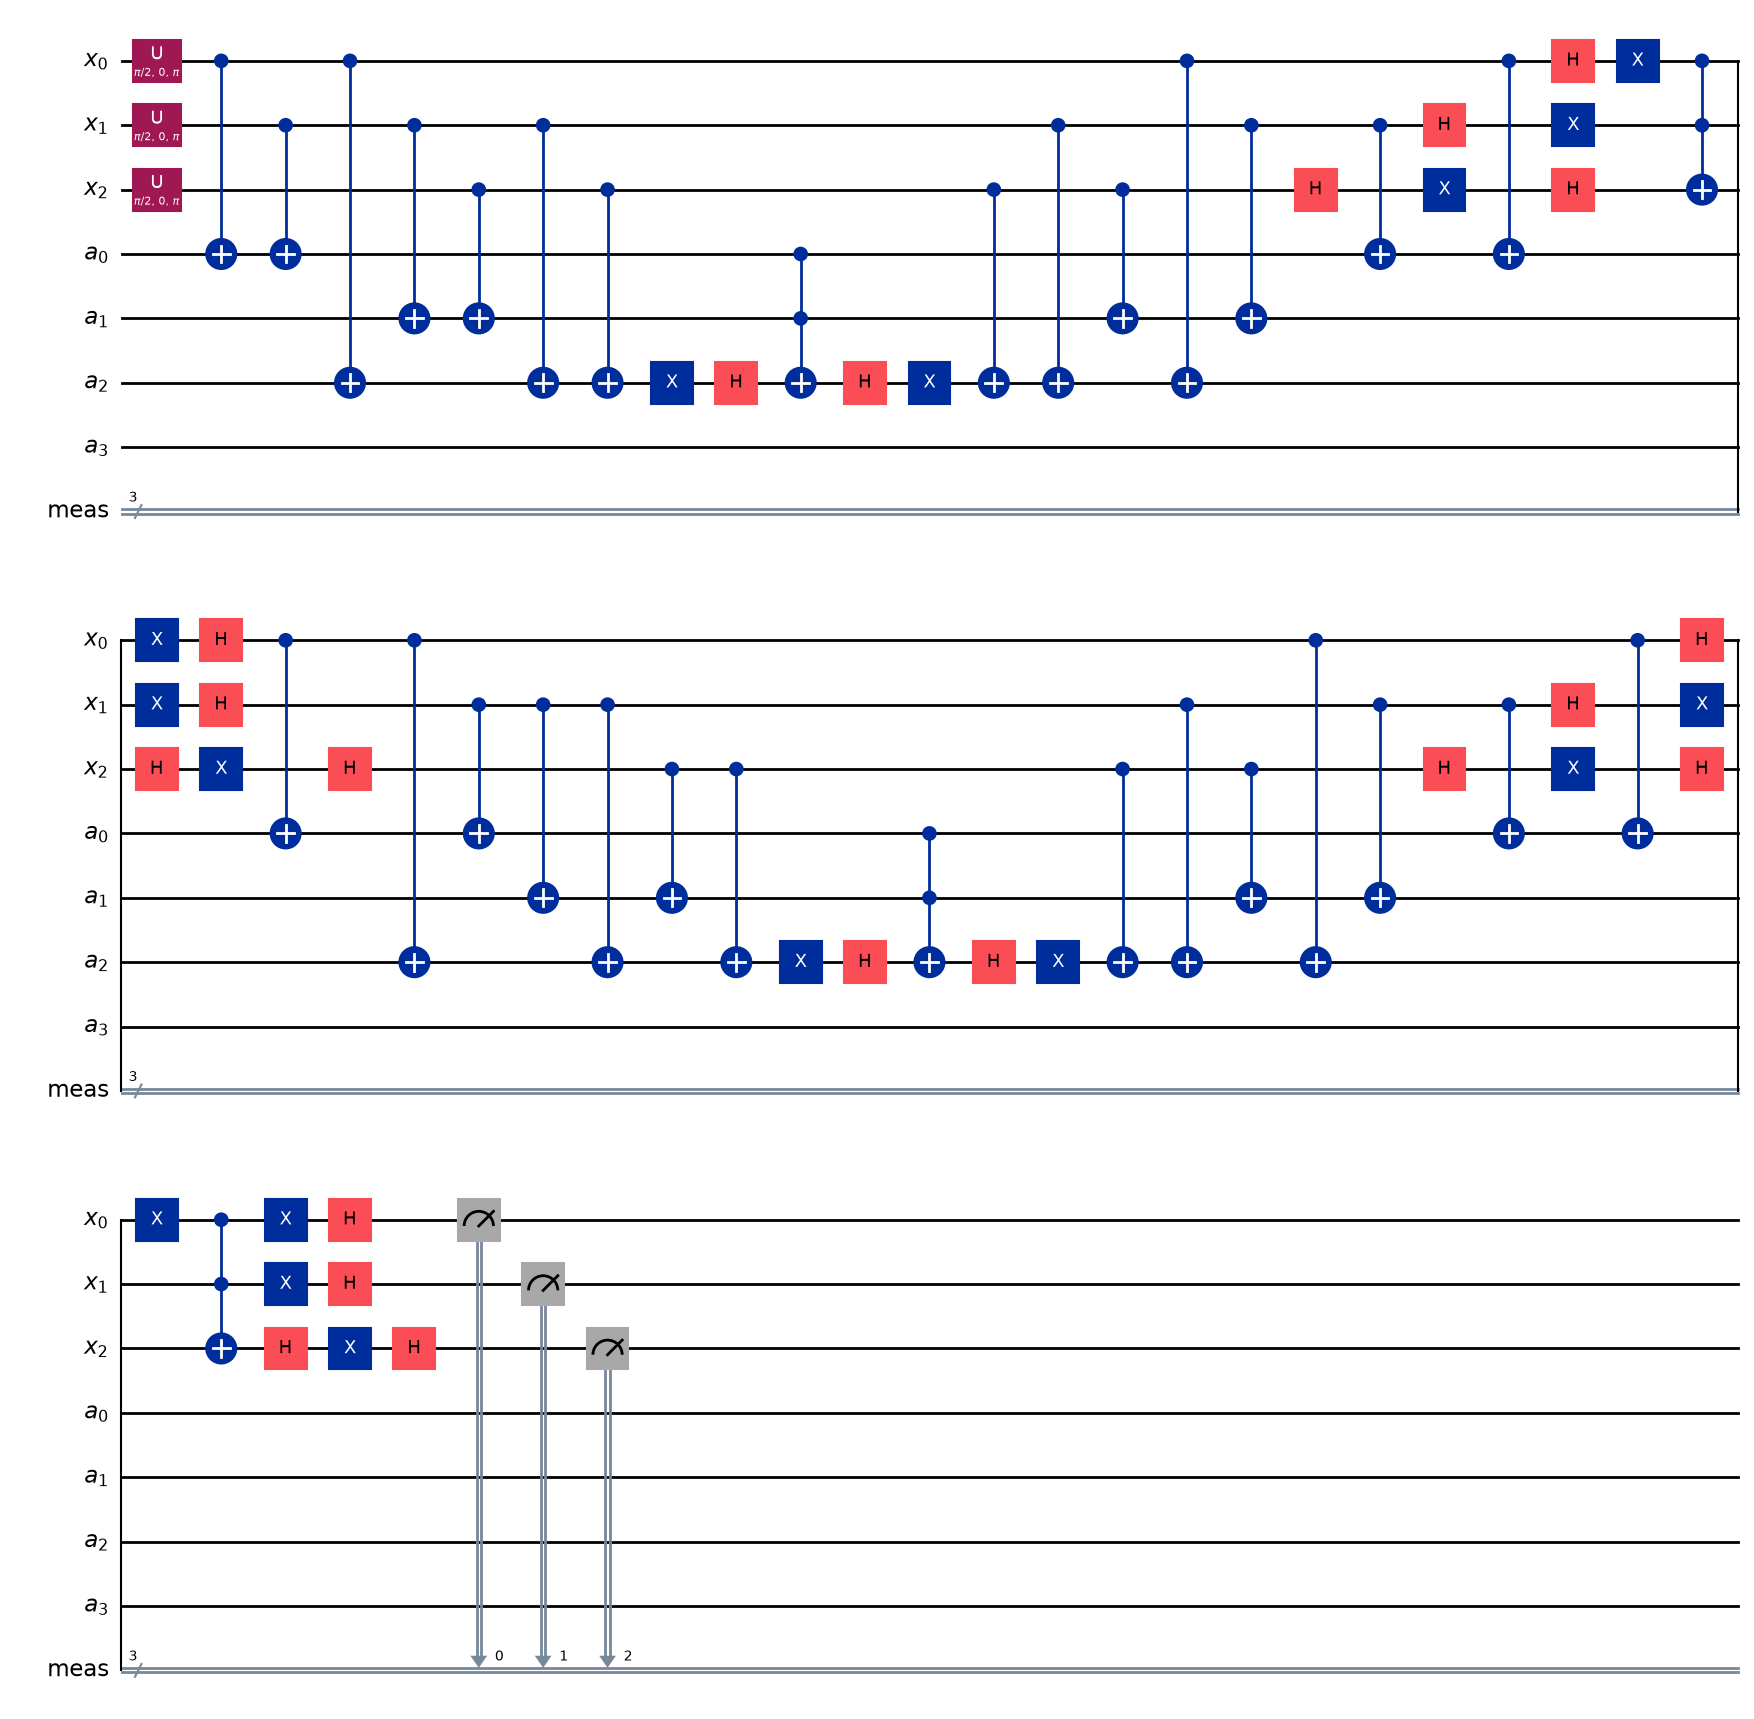

In [4]:
x = QuantumRegister(3, "x")
a = QuantumRegister(4, "a")
meas = ClassicalRegister(3, "meas")

qc = QuantumCircuit(x, a, meas)
# Create superposition over the data qubits only
qc.h(x)
# Apply 2 iterations of the Grover operator
qc.compose(grover_op.power(2), inplace=True)
# Measure only the data qubits
qc.measure(x, meas)
qc.decompose().draw(output="mpl", style="iqp")

In [5]:
from qiskit_ibm_runtime import QiskitRuntimeService

service = QiskitRuntimeService()
backend = service.least_busy(operational=True, simulator=False)
print(backend.name)

target = backend.target
pm = generate_preset_pass_manager(target=target, optimization_level=3)
circuit_isa = pm.run(qc)

ibm_marrakesh


In [6]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

sampler = Sampler(mode=backend)
sampler.options.default_shots = 10_000
result = sampler.run([circuit_isa]).result()
dist = result[0].data.meas.get_counts()

C:\Users\compu\AppData\Local\Temp\ipykernel_25724\1043456305.py:3: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


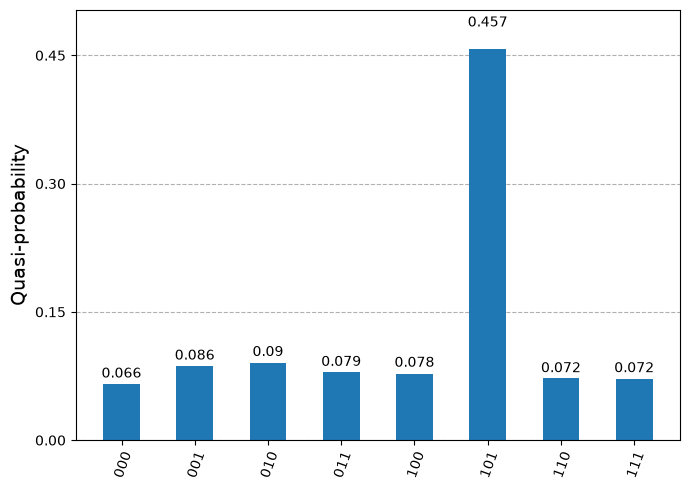

In [7]:
plot_distribution(dist)